## Resources

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = "/content/Airbnb_Open_Data.csv"
df = pd.read_csv(file_path, low_memory=False)
display(df.head())

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [4]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

In [5]:
print(df.isnull().sum())

id                                    0
NAME                                203
host id                               0
host_identity_verified              217
host name                           277
neighbourhood group                  29
neighbourhood                        16
lat                                   8
long                                  8
country                             323
country code                         86
instant_bookable                     86
cancellation_policy                  57
room type                             1
Construction year                   191
price                               165
service fee                         168
minimum nights                      364
number of reviews                   152
last review                       10708
reviews per month                 10694
review rate number                  233
calculated host listings count      145
availability 365                    439
house_rules                       33221


In [6]:
df['last review'] = pd.to_datetime(df['last review'], errors='coerce')

df.fillna({'reviews per month': 0, 'last review': df['last review'].min()}, inplace=True)

df.dropna(subset=['NAME', 'host name'], inplace=True)

print("Missing values after initial cleaning:")
print(df[['last review', 'reviews per month', 'NAME', 'host name']].isnull().sum())

Missing values after initial cleaning:
last review          0
reviews per month    0
NAME                 0
host name            0
dtype: int64


In [8]:
df['price'] = df['price'].replace(r'[\$,]', '', regex=True).astype(float)
df['service fee'] = df['service fee'].replace(r'[\$,]', '', regex=True).astype(float)

print("Price and service fee columns cleaned. Column types:")
print(df[['price', 'service fee']].dtypes)
display(df[['price', 'service fee']].head())

Price and service fee columns cleaned. Column types:
price          float64
service fee    float64
dtype: object


,price,service fee
0,966.0,193.0
1,142.0,28.0
2,620.0,124.0
4,204.0,41.0
5,577.0,115.0


In [9]:
df.drop_duplicates(inplace=True)
print(f"Number of remaining records: {len(df)}")

Number of remaining records: 65341


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 65341 entries, 0 to 65814
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              65341 non-null  int64         
 1   NAME                            65341 non-null  object        
 2   host id                         65341 non-null  int64         
 3   host_identity_verified          65137 non-null  object        
 4   host name                       65341 non-null  object        
 5   neighbourhood group             65315 non-null  object        
 6   neighbourhood                   65325 non-null  object        
 7   lat                             65333 non-null  float64       
 8   long                            65333 non-null  float64       
 9   country                         65024 non-null  object        
 10  country code                    65264 non-null  object        
 11  instant

In [11]:
print(df.describe())

                 id       host id           lat          long  \
count  6.534100e+04  6.534100e+04  65333.000000  65333.000000   
mean   1.919236e+07  4.934297e+10     40.728093    -73.949295   
min    1.001254e+06  1.303496e+08     40.499790    -74.249840   
25%    1.008115e+07  2.465454e+10     40.688610    -73.982900   
50%    1.922889e+07  4.920112e+10     40.722670    -73.954550   
75%    2.828993e+07  7.413272e+10     40.762770    -73.931670   
max    3.735041e+07  9.876313e+10     40.916970    -73.705220   
std    1.049617e+07  2.854219e+10      0.055911      0.050255   

       Construction year         price   service fee  minimum nights  \
count       65164.000000  65179.000000  65173.000000    64983.000000   
mean         2012.488659    624.263950    124.807298        8.130049   
min          2003.000000     50.000000     10.000000    -1223.000000   
25%          2008.000000    338.000000     67.000000        1.000000   
50%          2012.000000    624.000000    125.000000  

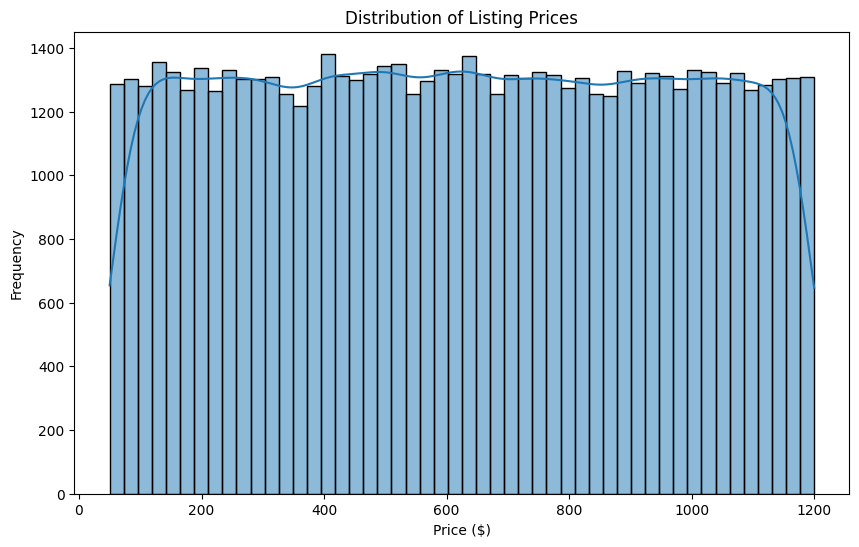

In [12]:
plt.figure(figsize=(10, 6))
sns.histplot(df['price'].dropna(), bins=50, kde=True)
plt.title('Distribution of Listing Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.show()

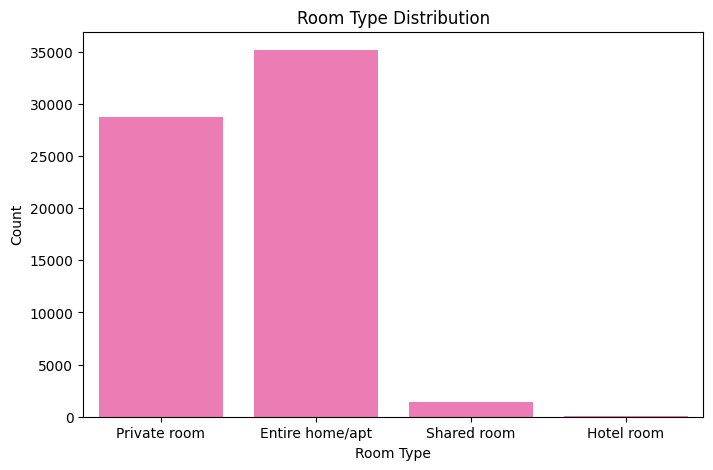

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(x='room type', data=df, color='hotpink')
plt.title('Room Type Distribution')
plt.xlabel('Room Type')
plt.ylabel('Count')
plt.show()

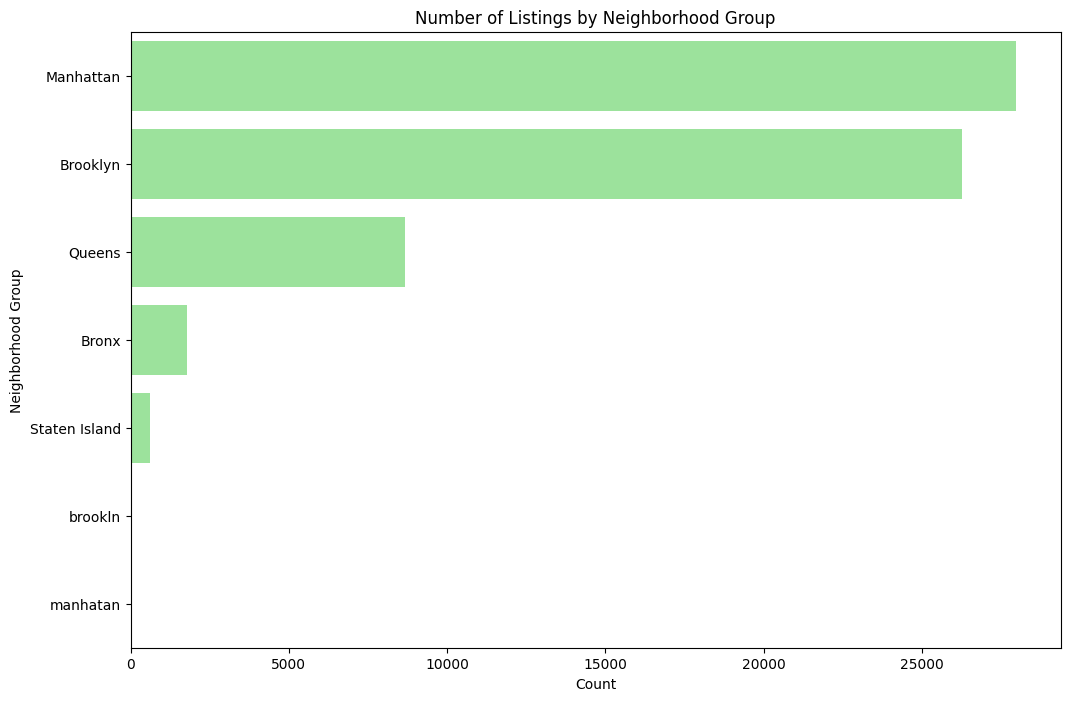

In [14]:
plt.figure(figsize=(12, 8))
sns.countplot(y='neighbourhood group', data=df, color='lightgreen', order=df['neighbourhood group'].value_counts().index)
plt.title('Number of Listings by Neighborhood Group')
plt.xlabel('Count')
plt.ylabel('Neighborhood Group')
plt.show()

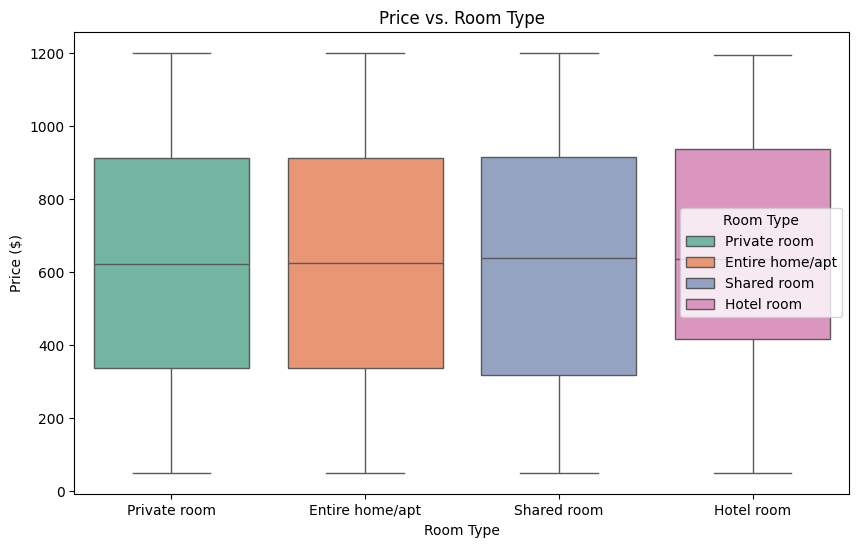

In [15]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='room type', y='price', hue='room type', data=df, palette='Set2')
plt.title('Price vs. Room Type')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.legend(title='Room Type')
plt.show()

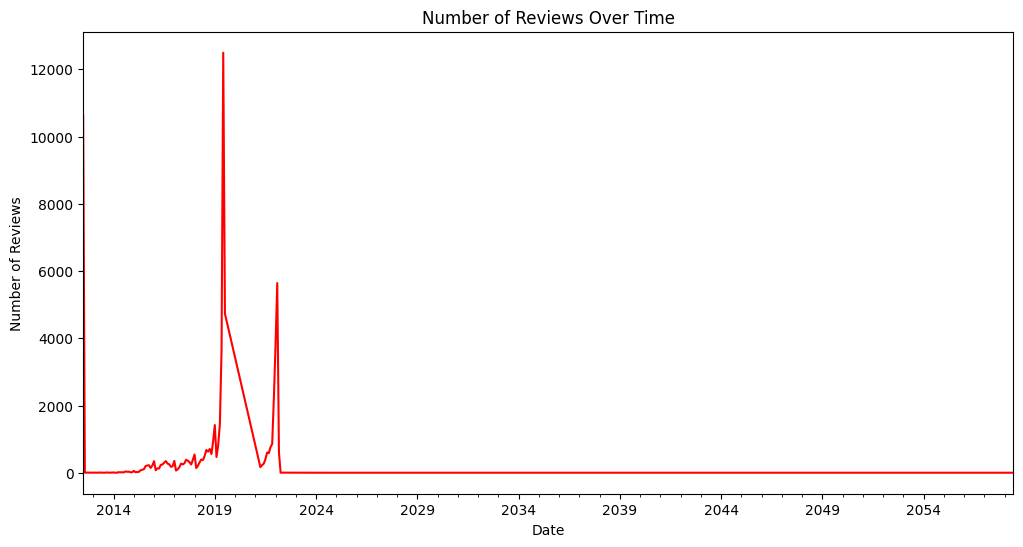

In [16]:
df['last review'] = pd.to_datetime(df['last review'])
reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size()

plt.figure(figsize=(12, 6))
reviews_over_time.plot(kind='line', color='red')
plt.title('Number of Reviews Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.show()